# 02 – Phase 2 source data: all four UCI cohorts

This executed notebook makes every Phase 2 source cohort visible, verifies its provenance, shows sample rows, and compares target balance and missingness. It is descriptive only; no model is fitted.

In [1]:
import os, sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.phase2.yaml').exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

## 1. Source and inclusion rule

Source: [UCI Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease), DOI `10.24432/C52P4X`, CC BY 4.0. Phase 2 uses exactly the four independent `processed.*.data` cohorts. Raw and reprocessed alternatives are not additional patients and are excluded to avoid duplication.

In [2]:
import contextlib, io
import pandas as pd
from IPython.display import Image, Markdown, display
from src.data.loader import FEATURE_COLUMNS, load_all_cohorts
from src.data.verify_phase2 import main as verify_phase2

with contextlib.redirect_stdout(io.StringIO()):
    verification = verify_phase2()  # also extracts the four files into data/raw/
df = load_all_cohorts()
source_table = pd.DataFrame([
    {
        'cohort': cohort,
        'source_file': verification['cohort_source_files'][cohort],
        'rows': values['n_rows'],
        'negative': values['negative'],
        'positive': values['positive'],
        'missing_predictor_cells': values['missing_predictor_cells'],
        'sha256': verification['cohort_file_sha256'][cohort],
    }
    for cohort, values in verification['cohorts'].items()
])
source_table

,cohort,source_file,rows,negative,positive,missing_predictor_cells,sha256
0,Cleveland,data/raw/processed.cleveland.data,303,164,139,6,a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f...
1,Hungarian,data/raw/processed.hungarian.data,294,188,106,782,d1ad108f785768cd3d7e82dc522e6f5a61eea93cccfb3a...
2,Switzerland,data/raw/processed.switzerland.data,123,8,115,273,834a405ccf5b66ab4056bb77794adc8df0b7125186454c...
3,VA,data/raw/processed.va.data,200,51,149,698,e7c93d8d0d2acdadfa4c5e8de768e2191e7f618b952e29...


## 2. Sample rows from every source cohort

In [3]:
for cohort in source_table['cohort']:
    display(Markdown(f'### {cohort}'))
    display(df.loc[df.cohort == cohort, ['cohort_patient_id', *FEATURE_COLUMNS, 'num', 'target']].head(3))

### Cleveland

,cohort_patient_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,Cleveland:0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,Cleveland:1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,Cleveland:2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1


### Hungarian

,cohort_patient_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
303,Hungarian:0,28.0,1.0,2.0,130.0,132.0,0.0,2.0,185.0,0.0,0.0,NaN,NaN,NaN,0,0
304,Hungarian:1,29.0,1.0,2.0,120.0,243.0,0.0,0.0,160.0,0.0,0.0,NaN,NaN,NaN,0,0
305,Hungarian:2,29.0,1.0,2.0,140.0,NaN,0.0,0.0,170.0,0.0,0.0,NaN,NaN,NaN,0,0


### Switzerland

,cohort_patient_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
597,Switzerland:0,32.0,1.0,1.0,95.0,0.0,NaN,0.0,127.0,0.0,0.7,1.0,NaN,NaN,1,1
598,Switzerland:1,34.0,1.0,4.0,115.0,0.0,NaN,NaN,154.0,0.0,0.2,1.0,NaN,NaN,1,1
599,Switzerland:2,35.0,1.0,4.0,NaN,0.0,NaN,0.0,130.0,1.0,NaN,NaN,NaN,7.0,3,1


### VA

,cohort_patient_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
720,VA:0,63.0,1.0,4.0,140.0,260.0,0.0,1.0,112.0,1.0,3.0,2.0,NaN,NaN,2,1
721,VA:1,44.0,1.0,4.0,130.0,209.0,0.0,1.0,127.0,0.0,0.0,NaN,NaN,NaN,0,0
722,VA:2,60.0,1.0,4.0,132.0,218.0,0.0,1.0,140.0,1.0,1.5,3.0,NaN,NaN,2,1


## 3. Target balance and missingness by cohort

In [4]:
balance = (df.groupby('cohort')['target']
             .agg(patients='size', positive='sum', positive_rate='mean')
             .assign(negative=lambda x: x.patients - x.positive))
display(balance[['patients', 'negative', 'positive', 'positive_rate']])

missingness = df.groupby('cohort')[FEATURE_COLUMNS].apply(lambda x: x.isna().sum()).T
display(missingness.style.background_gradient(cmap='Reds', axis=None))

,patients,negative,positive,positive_rate
cohort,,,,
Cleveland,303,164,139,0.458746
Hungarian,294,188,106,0.360544
Switzerland,123,8,115,0.934959
VA,200,51,149,0.745000


cohort,Cleveland,Hungarian,Switzerland,VA
age,0,0,0,0
sex,0,0,0,0
cp,0,0,0,0
trestbps,0,1,2,56
chol,0,23,0,7
fbs,0,8,75,7
restecg,0,1,1,0
thalach,0,1,1,53
exang,0,1,1,53
oldpeak,0,0,6,56


## 4. Combined cohort audit figure

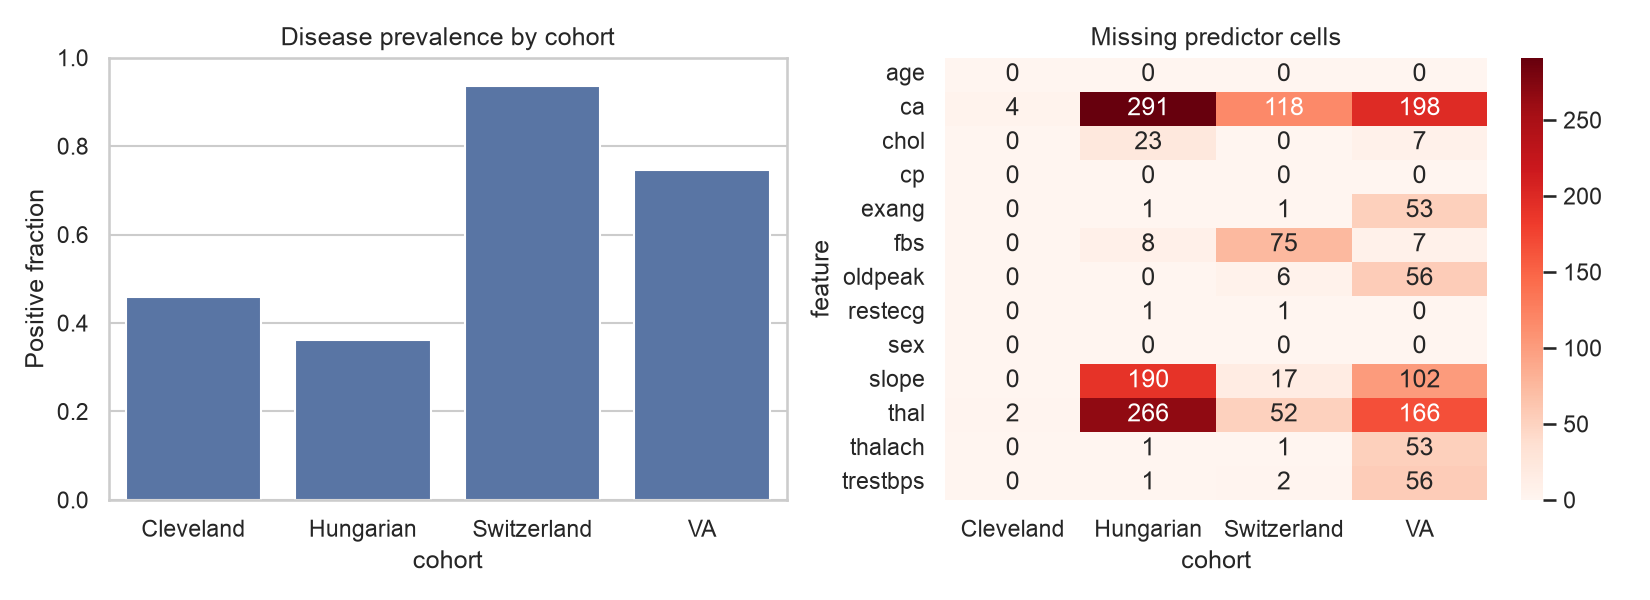

In [5]:
from src.data.eda_phase2 import run as run_phase2_eda

eda_summary = run_phase2_eda()
display(Image(str(ROOT / 'results/phase2/main/figures/cohort_data_audit.png')))

## 5. What the audit means

- The combined dataset contains **920** rows: 509 positive and 411 negative.
- Switzerland and VA are strongly imbalanced, so results are also reported by held-out cohort.
- Missingness is extensive outside Cleveland, especially for `ca`, `thal`, and `slope`; rows are not deleted.
- Imputation, encoding, scaling, and discretisation are fitted inside training folds only.
- The data are historical and referral-selected. These experiments are not clinical validation.